* Entradas:
$
\left[ \begin{matrix}
   0 & 0  \\
   0 & 1  \\
   1 & 0  \\
   1 & 1  \\
\end{matrix} \right]
$

* Saídas: 
$\left[ \begin{matrix}
   0  \\
   1  \\
   1  \\
   1  \\
\end{matrix} \right]$


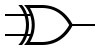

In [6]:
import tensorflow as tf
import numpy as np

X = np.array([[0,0], 
              [0,1], 
              [1,0], 
              [1,1]])
X

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

In [7]:
y = np.array([[1], 
              [0], 
              [0], 
              [1]])
y

array([[1],
       [0],
       [0],
       [1]])

In [8]:
neuronios_entrada = 2
neuronios_oculta = 3
neuronios_saida = 1

In [9]:
W = {'oculta': tf.Variable(tf.random_normal([neuronios_entrada, neuronios_oculta]), name = 'w_oculta'), 
     'saida': tf.Variable(tf.random_normal([neuronios_oculta, neuronios_saida]), name = 'w_saida')}

TypeError: ignored

In [ ]:
type(W)

In [ ]:
type(W['oculta'])

In [ ]:
W['oculta']

In [ ]:
W['saida']

In [ ]:
distribuicao = np.random.normal(size = 500)
#distribuicao
import seaborn as sns
%matplotlib inline
sns.distplot(distribuicao)

In [ ]:
b = {'oculta': tf.Variable(tf.random_normal([neuronios_oculta]), name = 'b_oculta'),
     'saida': tf.Variable(tf.random_normal([neuronios_saida]), name = 'b_saida')}

In [ ]:
xph = tf.placeholder(tf.float32, [4, neuronios_entrada], name = 'xph')
yph = tf.placeholder(tf.float32, [4, neuronios_saida], name = 'yph')

In [ ]:
camada_oculta = tf.add(tf.matmul(xph, W['oculta']), b['oculta'])
camada_oculta_ativacao = tf.sigmoid(camada_oculta)
camada_saida = tf.add(tf.matmul(camada_oculta_ativacao, W['saida']), b['saida'])
camada_saida_ativacao = tf.sigmoid(camada_saida)
erro = tf.losses.mean_squared_error(yph, camada_saida_ativacao)
otimizador = tf.train.GradientDescentOptimizer(learning_rate = 0.3).minimize(erro)

In [ ]:
init = tf.global_variables_initializer()

In [ ]:
with tf.Session() as sess:
    sess.run(init)
    #print(sess.run(W['oculta']))
    #print(sess.run(W['saida']))
    #print(sess.run(b['oculta']))
    #print('\n')
    #print(sess.run(b['saida']))
    #print(sess.run(camada_oculta, feed_dict = {xph: X}))
    #print(sess.run(camada_oculta_ativacao, feed_dict = {xph: X}))
    #print(sess.run(camada_saida, feed_dict = {xph: X}))
    #print(sess.run(camada_saida_ativacao, feed_dict = {xph: X}))
    for epocas in range(10000):
        erro_medio = 0
        _, custo = sess.run([otimizador, erro], feed_dict = {xph: X, yph: y})
        if epocas % 200 == 0:
            #print(custo)
            erro_medio += custo / 4
            print(erro_medio)
    W_final, b_final = sess.run([W, b])
            

0.06281377375125885
0.06256651878356934
0.06253638863563538
0.06251109391450882
0.062486086040735245
0.062457188963890076
0.06241883337497711
0.06236151605844498
0.06226633861660957
0.062091708183288574
0.06173840910196304
0.0609598346054554
0.05916708707809448
0.055213894695043564
0.04775196686387062
0.03625539690256119
0.023227393627166748
0.013901830650866032
0.008813797496259212
0.0060809762217104435
0.004499789327383041
0.003508562920615077
0.002844051690772176
0.002374144271016121
0.002027465496212244
0.0017628681380301714
0.0015552460681647062
0.0013885670341551304
0.0012521727476269007
0.0011387349804863334
0.0010430729016661644
0.0009614211157895625
0.0008909947937354445
0.0008296862943097949
0.0007758756983093917
0.000728301121853292
0.0006859637214802206
0.000648061279207468
0.0006139488541521132
0.0005830968730151653
0.0005550706409849226
0.0005295046721585095
0.0005060972180217505
0.00048459030222147703
0.00046476683928631246
0.0004464402445591986
0.00042945053428411484
0.

In [ ]:
W_final

{'oculta': array([[-3.5366604, -5.8264346, -4.2535715],
        [-2.8692062,  4.761803 ,  5.7585716]], dtype=float32),
 'saida': array([[ 3.3355477],
        [-7.7334876],
        [ 7.263449 ]], dtype=float32)}

In [ ]:
b_final

{'oculta': array([ 0.21722403, -2.4004495 ,  1.7168214 ], dtype=float32),
 'saida': array([-3.7106764], dtype=float32)}

In [ ]:
# teste
camada_oculta_teste = tf.add(tf.matmul(xph, W_final['oculta']), b_final['oculta'])
camada_oculta_ativacao_teste = tf.sigmoid(camada_oculta_teste)
camada_saida_teste = tf.add(tf.matmul(camada_oculta_ativacao_teste, W_final['saida']), b_final['saida'])
camada_saida_ativacao_teste = tf.sigmoid(camada_saida_teste)

In [ ]:
with tf.Session() as sess:
    sess.run(init)
    print(sess.run(camada_saida_ativacao_teste, feed_dict = {xph: X}))

[[0.97471523]
 [0.03561402]
 [0.0446284 ]
 [0.95463276]]
